# _**Matsch_P2_Ref_007: fidelity run against GEOtop 3.0**_

    -Authors: GEO2GEO project (Waterjade for Rigonian Lab)
    -License: GPL v3, as WHETGEO-1D
-----
The snow+soil column (`SnowSoilSolver1DMain`, configuration *fidelity*) against GEOtop 3.0 (commit 1f1fc5af) on the official 1D test **Matsch_P2_Ref_007 without canopy and corrected** (`casi/Matsch_P2_Ref_007/run.sh corretta`): `CanopyFraction = 0`, and three errors of the official case removed. The three errors:

- the meteo file's `JDfrom0` column was one day behind its dates, and GEOtop trusts it (`fixing_dates`, `meteodata.cc:583`). The column is dropped and the dates come from `Date`. This needs the inline `!` comments stripped from `geotop.inpts`: GEOtop's parser keeps them, so `MeteoStationStandardTime = 1 ! added by ... 2.1` was read as 1e21;
- `ActualOrProjectedArea = 1`, without which GEOtop projects the precipitation twice in a point simulation (`energy.balance.cc:299-304`);
- an empty `CloudTrans` column, which stops GEOtop from computing the daily cloudiness from the measured shortwave (`input.cc:405-408`).

This reference no longer equals the official test output. Station P2 in Val Mazia, 1549 m, slope 21.4°, 2 October to 2 November 2009, steps of 900 s, hourly outputs.

**What the comparison tests.** The forcing is GEOtop's own. The temporary tools of `core.snowsoil.fidelity` compute it from GEOtop's input files and reproduce the point output of the corrected run to the printed digits (`GeotopForcingTest`); every quantity agrees within 5e-7, including the averaged cloudiness. Two things come from GEOtop's *output* instead (the fallback of DN-14), because the column does not compute them:

- the **bare-soil surface temperature** `Tsurface`, imposed as a Dirichlet top when there is no snow (the column has no bare-soil energy balance);
- the **soil evaporation** `Evap_surface`, a sink of the top cell without snow (evapotranspiration comes from GEOET in GEOframe).

So this is a **conditioned comparison** (VAL-1): without snow it tests the soil (heat, Richards, freezing) under GEOtop's surface temperature; with snow it tests the snowpack and its surface balance.

**Tolerances.** The VAL-1 tolerances below were proposed before reading the results of the first run and **approved on 22 October 2026**.

Run `cases/snowsoil/matsch_p2_ref_007/run.sh` first: it writes the forcing and the outputs read here.

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from WHETGEO1D_SnowSoilOutputs import *
import warnings
warnings.filterwarnings('ignore')
plt.rcParams.update({"axes.edgecolor": "0.8", "axes.linewidth": 0.6, "grid.linewidth": 0.3, "font.family": "serif",
                     "axes.labelsize": 13, "font.size": 13, "legend.fontsize": 10})
pd.set_option('display.float_format', '{:.4g}'.format)

## Define input

In [2]:
case = os.environ.get('MATSCH_CASE', os.path.join('..', 'cases', 'snowsoil', 'matsch_p2_ref_007'))
ours_path = os.path.join(case, 'output')
geotop_path = os.path.join(case, 'geotop', 'output-tabs')

## Read both runs
The CSV files of the column carry GEOtop's names and units, and dates in GEOtop's local standard time (`outputStandardTime = 1`), so the columns align by name and the rows by date.

In [3]:
ours, header = read_csv(os.path.join(ours_path, 'point.csv'))
gt, _ = read_csv(os.path.join(geotop_path, 'point0001.txt'))
idx = ours.index.intersection(gt.index)
ours, gt = ours.loc[idx], gt.loc[idx]
print(len(idx), 'hours,', idx[0], '-', idx[-1])
for k in ['code_version', 'configuration', 'geotopSnowParameters', 'bareSoilTop', 'bottomBC', 'soilWaterBottomBC']:
    print(f'{k:22s} {header.get(k)}')
profiles = {}
# GEOtop's soilTz is its SoilAveragedTempProfileFile, the mean over the hour: it is compared with the
# column's soilTzav.csv (mean over the record); thetaliq, thetaice and psiz are instantaneous in both
for name, ours_name, geotop_name in [('soilTz', 'soilTzav', 'soilTz0001'), ('thetaliq', 'thetaliq', 'thetaliq0001'),
                                     ('thetaice', 'thetaice', 'thetaice0001'), ('psiz', 'psiz', 'psiz0001')]:
    a, _ = read_csv(os.path.join(ours_path, ours_name + '.csv'))
    b, _ = read_csv(os.path.join(geotop_path, geotop_name + '.txt'))
    profiles[name] = (a.loc[idx, profile_columns(a)], b.loc[idx, profile_columns(b)])
depths = profile_columns(profiles['soilTz'][0])
print('soil cells [mm]:', depths)

767 hours, 2009-10-02 01:00:00 - 2009-11-02 23:00:00
code_version           whetgeo1d v1.2.9-last-version-before-api-review-127-gfe1dbda-dirty
configuration          fidelity
geotopSnowParameters   FreshSnowReflVis=0.88, FreshSnowReflNIR=0.63, SnowAgingCoeffVis=0.1108, AlbExtParSnow=182, IrriducibleWatSatSnow=0.0595, SnowEmissiv=0.99, SnowRoughness=1.6, DrySnowDefRate=1.01, WetSnowDefRate=2.49, SnowDensityCutoff=100, SnowViscosity=1e6, MaxWaterEqSnowLayerContent=10, SWEbottom=50, SWEtop=2000, MaxSnowLayersMiddle=50, PointSlope=21.4, SoilRoughness=100, ThresSnowSoilRough=100, SoilEmissiv=0.96
bareSoilTop            DIRICHLET
bottomBC               BOTTOM_NEUMANN
soilWaterBottomBC      BOTTOM_IMPERVIOUS
soil cells [mm]: [5.0, 15.0, 25.0, 40.0, 60.0, 85.0, 125.0, 175.0, 225.0, 275.0, 350.0, 450.0, 550.0, 650.0, 775.0, 925.0]


## Tolerances (VAL-1, approved 22 October 2026)

In [4]:
tolerances = {
    'snow depth RMSE [mm]': 2.0,
    'snow depth max |diff| [mm]': 5.0,
    'SWE RMSE [mm]': 0.2,
    'SWE peak, relative': 0.10,
    'melt total, relative': 0.10,
    'snow runoff total, relative': 0.10,
    'Tsurface with snow RMSE [K]': 0.5,
    'surface fluxes with snow RMSE [W/m2]': 5.0,
    'soil T bias [K]': 0.1,
    'soil T RMSE [K]': 0.2,
    'theta_liq RMSE [-]': 0.01,
    'theta_ice max, top cell [-]': 0.02,
    'frost depth max [cells]': 0,
}
pd.Series(tolerances)

snow depth RMSE [mm]                      2
snow depth max |diff| [mm]                5
SWE RMSE [mm]                           0.2
SWE peak, relative                      0.1
melt total, relative                    0.1
snow runoff total, relative             0.1
Tsurface with snow RMSE [K]             0.5
surface fluxes with snow RMSE [W/m2]      5
soil T bias [K]                         0.1
soil T RMSE [K]                         0.2
theta_liq RMSE [-]                     0.01
theta_ice max, top cell [-]            0.02
frost depth max [cells]                   0
dtype: float64

## Snow

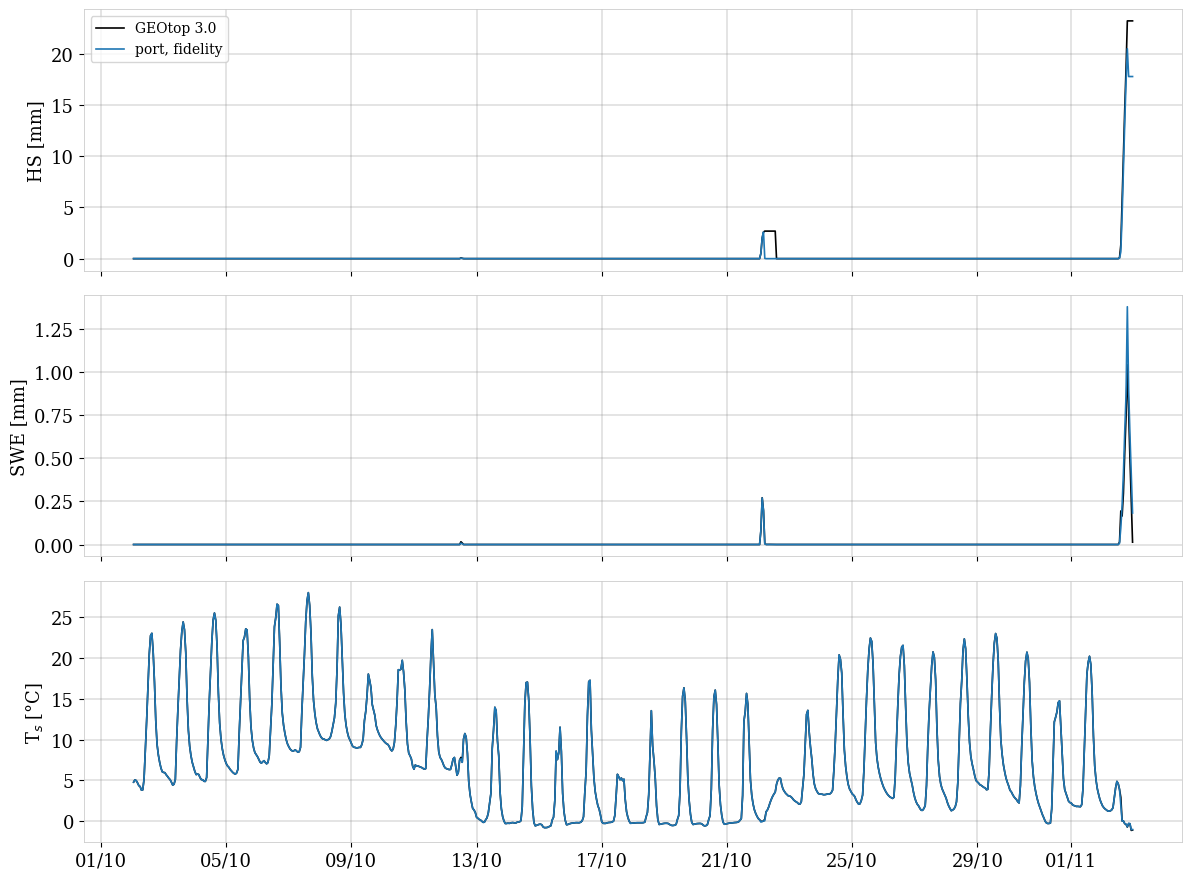

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for a, col, label in [(ax[0], 'snow_depth[mm]', 'HS [mm]'), (ax[1], 'snow_water_equivalent[mm]', 'SWE [mm]'),
                      (ax[2], 'Tsurface[C]', 'T$_s$ [°C]')]:
    a.plot(gt.index.to_numpy(), gt[col].to_numpy(), 'k', lw=1.2, label='GEOtop 3.0')
    a.plot(ours.index.to_numpy(), ours[col].to_numpy(), 'C0', lw=1.2, label='port, fidelity')
    a.set_ylabel(label)
    a.grid(color='grey', linestyle='-', linewidth=0.3)
ax[0].legend()
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
plt.tight_layout()

The three snow events, closer: 11 October (a trace), 21 October and 1–2 November.

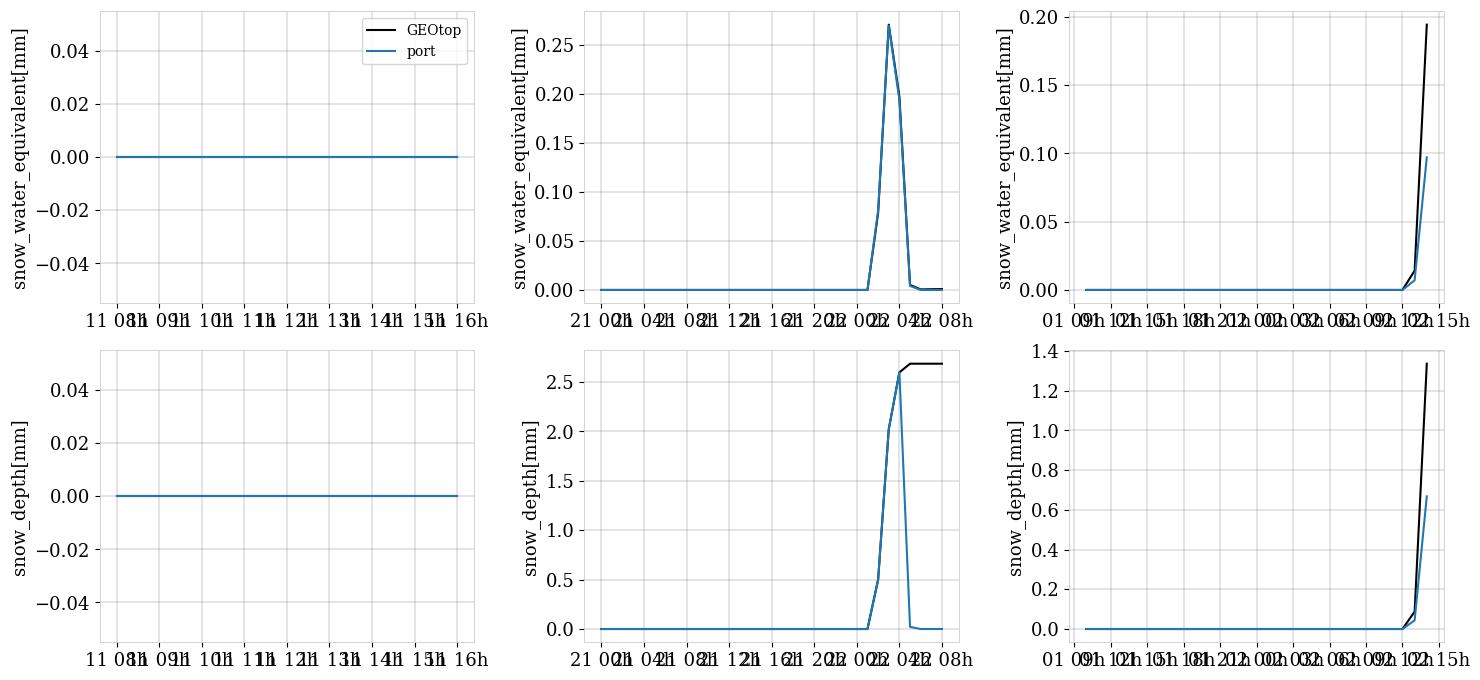

In [6]:
events = [('2009-10-11 08:00', '2009-10-11 16:00'), ('2009-10-21 00:00', '2009-10-22 08:00'), ('2009-11-01 10:00', '2009-11-02 14:00')]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, (a, b) in enumerate(events):
    o, g = ours.loc[a:b], gt.loc[a:b]
    for i, col in enumerate(['snow_water_equivalent[mm]', 'snow_depth[mm]']):
        ax[i, j].plot(g.index.to_numpy(), g[col].to_numpy(), 'k', label='GEOtop')
        ax[i, j].plot(o.index.to_numpy(), o[col].to_numpy(), 'C0', label='port')
        ax[i, j].set_ylabel(col)
        ax[i, j].xaxis.set_major_formatter(mdates.DateFormatter('%d %Hh'))
        ax[i, j].grid(color='grey', linestyle='-', linewidth=0.3)
ax[0, 0].legend()
plt.tight_layout()

Snow runoff: the column writes the outflow from the base of the pack (`snowRunoff`); GEOtop's point file has none. GEOtop's `Prain_rain_on_snow` is not the rain entering the pack (0.5 mm against the 3–6 mm that fall on snow in either model), so both runoffs are closed here the same way from hourly values: snowfall + rain falling while the pack of the previous hour exists − sublimation − ΔSWE (sublimation positive in both, checked on the totals). The column's own `snowRunoff` is listed too.

In [7]:
def rain_on_snow(d):
    return d['Prain_under_canopy[mm]'][d['snow_water_equivalent[mm]'].shift(1, fill_value=0.0) > 0].sum()

def closed_runoff(d):
    dswe = d['snow_water_equivalent[mm]'].iloc[-1] - d['snow_water_equivalent[mm]'].iloc[0]
    return d['Psnow_under_canopy[mm]'].sum() + rain_on_snow(d) - d['snow_subl[mm]'].sum() - dswe

runoff_gt, runoff_ours = closed_runoff(gt), closed_runoff(ours)
snow_table = pd.DataFrame({
    'GEOtop': [gt['snow_water_equivalent[mm]'].max(), gt['snow_depth[mm]'].max(), gt['snow_melted[mm]'].sum(), gt['snow_subl[mm]'].sum(),
               rain_on_snow(gt), runoff_gt, np.nan, (gt['snow_water_equivalent[mm]'] > 0).sum()],
    'port': [ours['snow_water_equivalent[mm]'].max(), ours['snow_depth[mm]'].max(), ours['snow_melted[mm]'].sum(), ours['snow_subl[mm]'].sum(),
             rain_on_snow(ours), runoff_ours, ours['snowRunoff[mm]'].sum(), (ours['snow_water_equivalent[mm]'] > 0).sum()]},
    index=['SWE max [mm]', 'HS max [mm]', 'melt [mm]', 'sublimation [mm]', 'rain on the pack [mm]', 'snow runoff, closed [mm]',
           'snow runoff, written [mm]', 'hours with snow'])
snow_table

,GEOtop,port
SWE max [mm],1.041,1.377
HS max [mm],23.19,20.48
melt [mm],3.728,3.035
sublimation [mm],0.03851,-0.03242
rain on the pack [mm],6.489,4.627
"snow runoff, closed [mm]",10.12,8.164
"snow runoff, written [mm]",NaN,7.345
hours with snow,25,17


## Surface fluxes with snow in both models
Without snow the column's surface is GEOtop's `Tsurface` and the column computes no balance (NaN), so the fluxes are compared only in the hours where both have snow.

In [8]:
both = (ours['snow_water_equivalent[mm]'] > 0) & (gt['snow_water_equivalent[mm]'] > 0)
flux_cols = ['SWnet[W/m2]', 'LWnet[W/m2]', 'H[W/m2]', 'LE[W/m2]', 'Tsurface[C]']
rows = {}
for col in flux_cols:
    d = (ours.loc[both, col] - gt.loc[both, col])
    rows[col] = {'hours': int(both.sum()), 'mean GEOtop': gt.loc[both, col].mean(), 'mean port': ours.loc[both, col].mean(),
                 'bias': d.mean(), 'RMSE': np.sqrt((d ** 2).mean())}
flux_table = pd.DataFrame(rows).T
flux_table

,hours,mean GEOtop,mean port,bias,RMSE
SWnet[W/m2],17,35.64,3.453,-0.9099,2.252
LWnet[W/m2],17,-20.88,-14.37,0.06068,0.437
H[W/m2],17,6.338,-6.2,-0.07062,0.6509
LE[W/m2],17,6.091,-2.356,-0.2689,1.094
Tsurface[C],17,1.032,0.9668,-0.06503,0.2326


## Soil temperature

GEOtop's `soilTz` file here is its `SoilAveragedTempProfileFile`: the soil temperature **averaged over the hour** (`output.cc:233-234`). Likewise, `Tsurface` in its point file is the mean of the steps of the hour. The column therefore writes both: `soilTz.csv`, the temperature at the end of the record, and `soilTzav.csv`, the mean over its steps. The point file's `Tsurface` is the mean too. Comparing GEOtop's hourly means with end-of-hour values had made a 0.2–0.7 K RMSE near the surface on clear days, when the top centimetres warm by several kelvin within the hour.

In [9]:
T_ours, T_gt = profiles['soilTz']
rows = {}
for d in depths:
    diff = T_ours[d] - T_gt[d]
    rows[d] = {'bias [K]': diff.mean(), 'RMSE [K]': np.sqrt((diff ** 2).mean()), 'max |diff| [K]': diff.abs().max(),
               'min GEOtop [C]': T_gt[d].min(), 'min port [C]': T_ours[d].min()}
soilT_table = pd.DataFrame(rows).T
soilT_table.index.name = 'depth [mm]'
soilT_table

,bias [K],RMSE [K],max |diff| [K],min GEOtop [C],min port [C]
depth [mm],,,,,
5,-0.01434,0.07751,1.245,-0.5875,-0.5876
15,-0.006412,0.07395,0.7037,-0.07736,-0.04065
25,-0.004259,0.0755,0.6348,0.1466,0.1583
40,-0.002007,0.06778,0.6354,0.4388,0.4506
60,-0.000221,0.05607,0.5517,0.8238,0.8355
85,0.002377,0.04796,0.4015,1.277,1.3
125,0.007359,0.04687,0.2386,1.964,1.972
175,0.01353,0.0544,0.2973,2.711,2.718
225,0.01911,0.06233,0.3367,3.34,3.345


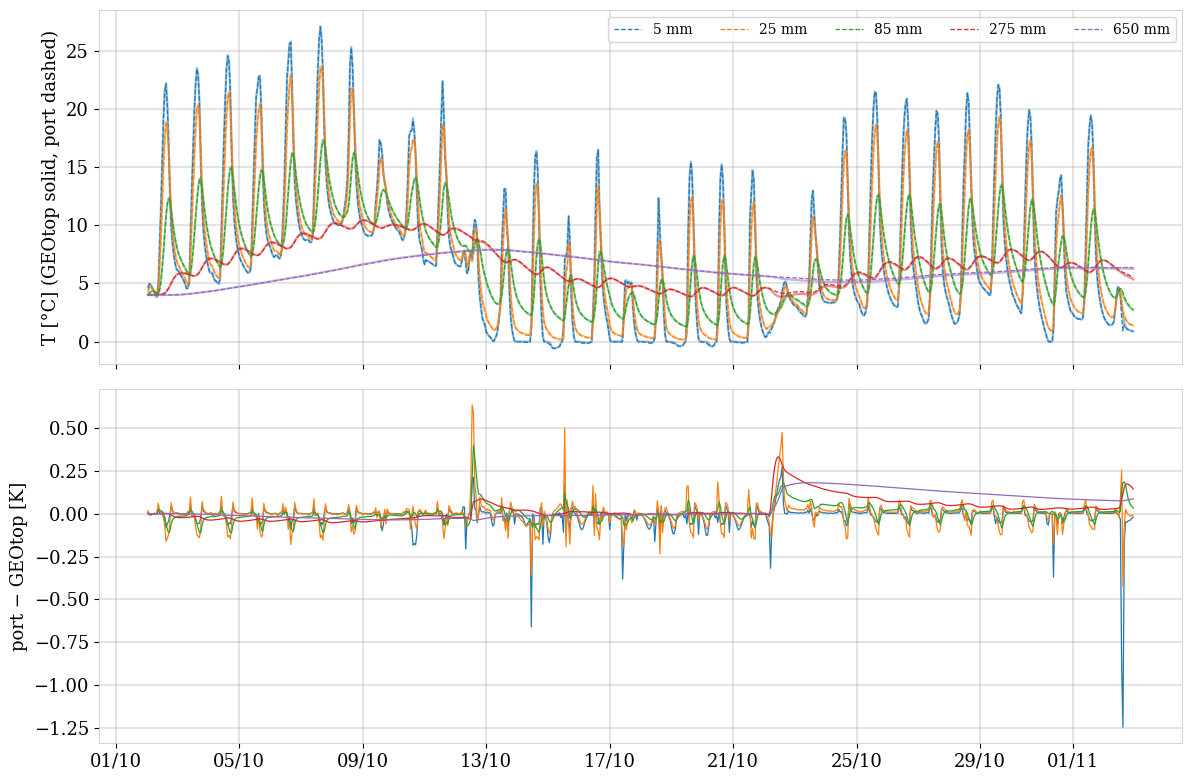

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for d, color in zip([5.0, 25.0, 85.0, 275.0, 650.0], ['C0', 'C1', 'C2', 'C3', 'C4']):
    ax[0].plot(T_gt.index.to_numpy(), T_gt[d].to_numpy(), color=color, lw=1.6, alpha=0.5)
    ax[0].plot(T_ours.index.to_numpy(), T_ours[d].to_numpy(), color=color, lw=0.9, ls='--', label=f'{d:.0f} mm')
    ax[1].plot(T_ours.index.to_numpy(), (T_ours[d] - T_gt[d]).to_numpy(), color=color, lw=0.9, label=f'{d:.0f} mm')
ax[0].set_ylabel('T [°C] (GEOtop solid, port dashed)')
ax[1].set_ylabel('port − GEOtop [K]')
ax[0].legend(ncol=5)
for a in ax:
    a.grid(color='grey', linestyle='-', linewidth=0.3)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
plt.tight_layout()

## Soil water and frozen soil
Liquid and ice content at the top cells, and the frost depth: the depth of the centre of the deepest cell with θ$_i$ > 10⁻³ (on the grid: cells of 10 mm at the top).

In [11]:
L_ours, L_gt = profiles['thetaliq']
I_ours, I_gt = profiles['thetaice']
rows = {}
for d in depths[:6]:
    rows[d] = {'theta_liq RMSE': np.sqrt(((L_ours[d] - L_gt[d]) ** 2).mean()), 'theta_liq bias': (L_ours[d] - L_gt[d]).mean(),
               'theta_ice max GEOtop': I_gt[d].max(), 'theta_ice max port': I_ours[d].max()}
water_table = pd.DataFrame(rows).T
water_table.index.name = 'depth [mm]'

def frost_depth(ice):
    cols = np.array(profile_columns(ice))
    frozen = ice[cols].values > 1e-3
    return pd.Series(np.where(frozen.any(axis=1), [cols[r].max() if r.any() else 0 for r in frozen], 0.0), index=ice.index)

fd_ours, fd_gt = frost_depth(I_ours), frost_depth(I_gt)
frost_table = pd.Series({'max frost depth GEOtop [mm]': fd_gt.max(), 'max frost depth port [mm]': fd_ours.max(),
                         'hours frozen GEOtop': int((fd_gt > 0).sum()), 'hours frozen port': int((fd_ours > 0).sum()),
                         'hours with a different frost cell': int((fd_gt != fd_ours).sum())})
display(water_table)
frost_table

,theta_liq RMSE,theta_liq bias,theta_ice max GEOtop,theta_ice max port
depth [mm],,,,
5,0.03343,-0.01259,0.3763,0.3558
15,0.005888,-0.002957,0.3097,0.2611
25,0.003756,-0.00355,0,0
40,0.003604,-0.003466,0,0
60,0.003438,-0.003348,0,0
85,0.003263,-0.003202,0,0


max frost depth GEOtop [mm]          15
max frost depth port [mm]            15
hours frozen GEOtop                 113
hours frozen port                   114
hours with a different frost cell     3
dtype: float64

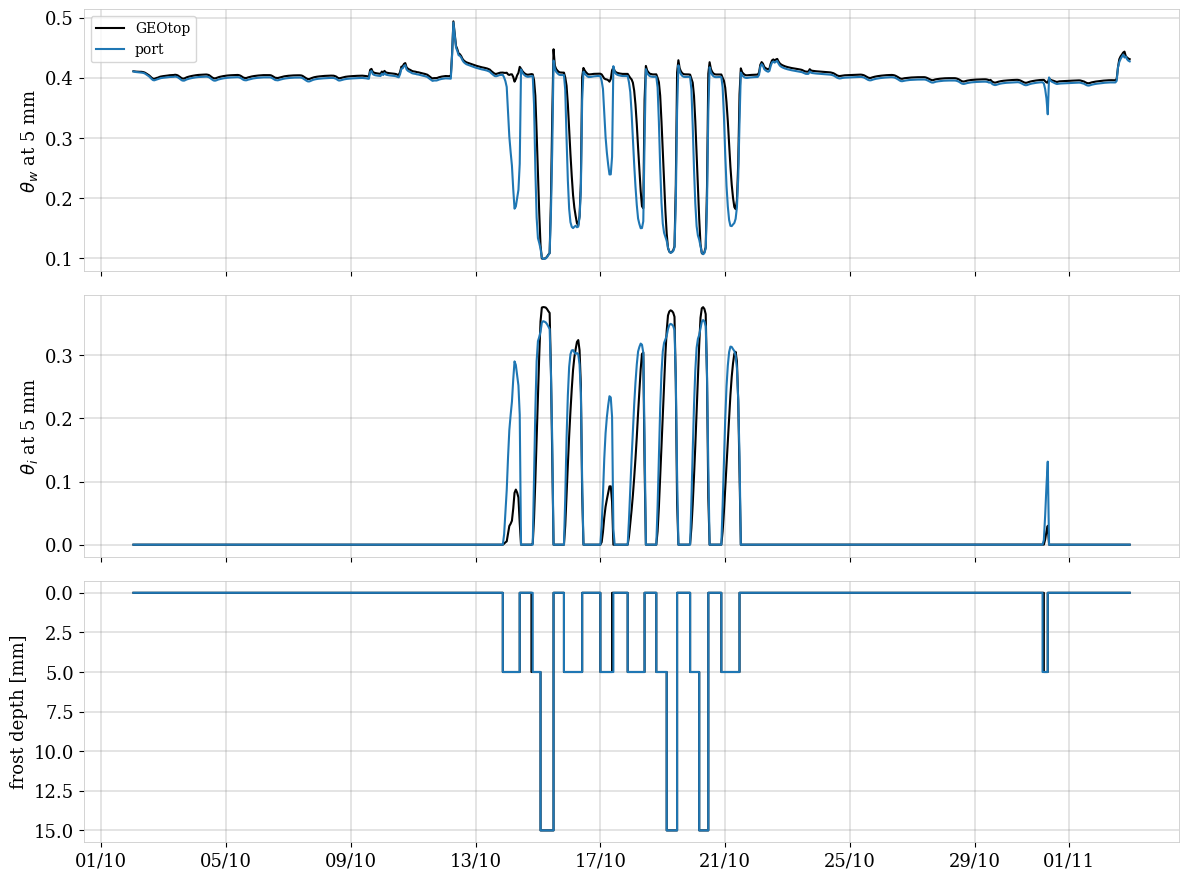

In [12]:
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(L_gt.index.to_numpy(), L_gt[5.0].to_numpy(), 'k', label='GEOtop')
ax[0].plot(L_ours.index.to_numpy(), L_ours[5.0].to_numpy(), 'C0', label='port')
ax[0].set_ylabel('$\\theta_w$ at 5 mm')
ax[1].plot(I_gt.index.to_numpy(), I_gt[5.0].to_numpy(), 'k')
ax[1].plot(I_ours.index.to_numpy(), I_ours[5.0].to_numpy(), 'C0')
ax[1].set_ylabel('$\\theta_i$ at 5 mm')
ax[2].step(fd_gt.index.to_numpy(), fd_gt.to_numpy(), 'k', where='pre')
ax[2].step(fd_ours.index.to_numpy(), fd_ours.to_numpy(), 'C0', where='pre')
ax[2].set_ylabel('frost depth [mm]')
ax[2].invert_yaxis()
ax[0].legend()
for a in ax:
    a.grid(color='grey', linestyle='-', linewidth=0.3)
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
plt.tight_layout()

## Against the tolerances

In [13]:
def rmse(a, b):
    return float(np.sqrt(((a - b) ** 2).mean()))

hs_o, hs_g = ours['snow_depth[mm]'], gt['snow_depth[mm]']
swe_o, swe_g = ours['snow_water_equivalent[mm]'], gt['snow_water_equivalent[mm]']
checks = [
    ('snow depth RMSE [mm]', rmse(hs_o, hs_g), tolerances['snow depth RMSE [mm]']),
    ('snow depth max |diff| [mm]', float((hs_o - hs_g).abs().max()), tolerances['snow depth max |diff| [mm]']),
    ('SWE RMSE [mm]', rmse(swe_o, swe_g), tolerances['SWE RMSE [mm]']),
    ('SWE peak, relative', abs(swe_o.max() / swe_g.max() - 1), tolerances['SWE peak, relative']),
    ('melt total, relative', abs(ours['snow_melted[mm]'].sum() / gt['snow_melted[mm]'].sum() - 1), tolerances['melt total, relative']),
    ('snow runoff total, relative', abs(runoff_ours / runoff_gt - 1), tolerances['snow runoff total, relative']),
    ('Tsurface with snow RMSE [K]', flux_table.loc['Tsurface[C]', 'RMSE'], tolerances['Tsurface with snow RMSE [K]']),
]
for col in ['SWnet[W/m2]', 'LWnet[W/m2]', 'H[W/m2]', 'LE[W/m2]']:
    checks.append((f'{col} with snow RMSE', flux_table.loc[col, 'RMSE'], tolerances['surface fluxes with snow RMSE [W/m2]']))
for d in [5.0, 15.0, 25.0, 85.0, 175.0, 450.0, 925.0]:
    checks.append((f'soil T {d:.0f} mm |bias| [K]', abs(soilT_table.loc[d, 'bias [K]']), tolerances['soil T bias [K]']))
    checks.append((f'soil T {d:.0f} mm RMSE [K]', soilT_table.loc[d, 'RMSE [K]'], tolerances['soil T RMSE [K]']))
for d in depths[:3]:
    checks.append((f'theta_liq {d:.0f} mm RMSE', water_table.loc[d, 'theta_liq RMSE'], tolerances['theta_liq RMSE [-]']))
checks.append(('theta_ice max 5 mm |diff|', abs(I_ours[5.0].max() - I_gt[5.0].max()), tolerances['theta_ice max, top cell [-]']))
cell = {d: i for i, d in enumerate(depths)}
checks.append(('frost depth max [cells]', abs(cell.get(fd_ours.max(), -1) - cell.get(fd_gt.max(), -1)), tolerances['frost depth max [cells]']))
summary = pd.DataFrame(checks, columns=['metric', 'value', 'tolerance']).set_index('metric')
summary['within'] = summary['value'] <= summary['tolerance']
summary

,value,tolerance,within
metric,,,
snow depth RMSE [mm],0.5076,2,True
snow depth max |diff| [mm],5.429,5,False
SWE RMSE [mm],0.01845,0.2,True
"SWE peak, relative",0.3224,0.1,False
"melt total, relative",0.1858,0.1,False
"snow runoff total, relative",0.1936,0.1,False
Tsurface with snow RMSE [K],0.2326,0.5,True
SWnet[W/m2] with snow RMSE,2.252,5,True
LWnet[W/m2] with snow RMSE,0.437,5,True


## Reading the differences

The forcing is not among the causes: the tools reproduce GEOtop's own forcing of the corrected run to the printed digits (`GeotopForcingTest`). The three snow events (12 October, a trace; 22 October; 2 November) are thin packs, never above 1 mm of SWE. The differences beyond the tolerances, with their attribution:

1. **HS of a melting pack (GEOtop behaviour, followed in fidelity).** On 2 November GEOtop's single layer keeps its thickness, 23.2 mm, while its SWE melts from 1.04 to 0.01 mm: the density falls to below 1 kg m⁻³. On 22 October GEOtop likewise keeps 2.7 mm of depth with 0.001 mm of SWE for a day. In `WBsnow` (`snow.cc:1093-1110`) a cell with at most 0.1 W$_c$ of ice (1 kg m⁻² here) is neither compacted nor shrunk by the melt. The fidelity configuration does the same (decision of 22 October 2026); the recommended one still shrinks every cell (SNOW-6).

   - *Conservation.* The rule changes thicknesses only. The column balance (VAL-7, printed at the end of each run) closes on both runs to 1·10⁻⁸ kg m⁻² and 0.03 J m⁻² in the worst step, all of it explained by the Richards and Newton residuals. `ThinCellShrinkageTest` melts a 0.4 kg m⁻² layer on warm soil under rain: mass and energy close step by step (column 1·10⁻¹⁴ kg m⁻² and 1·10⁻⁷ J m⁻²), the cell holds no free liquid, and its density falls from 133 to 58 kg m⁻³ as the ice goes. The density stays physical (positive, below ice) but becomes very low near the end, as in GEOtop.
   - *Peak depth.* With the rule and the skin, HS max is 20.5 / 19.7 mm (imposed / balance) against GEOtop's 23.2; without the rule it was 9–11 mm. The fresh snow is not the cause: from 16:00 to 19:00 each hour adds 4.0–4.7 mm in both models, the same fresh-snow density. The remaining 3 mm come from the first two hours of snowfall (13:00–15:00), which melt faster in the port while the soil is still warm. With the balance, HS max |diff| is 23.2 mm in one hour only: at 23:00 the port's last 0.01 mm of SWE melts away and merges into the soil, while GEOtop still holds 0.013 mm as a 23 mm layer.
2. **Thin snow (GEOtop's regime, now ported in fidelity).** The case's keywords are `SoilRoughness = 100`, `ThresSnowSoilRough = 100` and `SoilEmissiv = 0.96`. Below 100 mm of snow GEOtop takes the soil roughness (100 mm against 1.6 mm), and below 10 mm the soil emissivity. GEOtop also merges a single snow layer that melts away within a step into the soil, and solves that step as bare soil (`sux = -6`, `energy.balance.cc:702-729, 2130-2141`).

   - *Before the merge was ported,* the port kept such a layer as an all-liquid "snow" cell. On 12 October at 12:00–13:00, a trace of snow (0.008 mm) sat at +7 °C and evaporated at the potential rate of a wet surface. This gave LE of 90–106 W m⁻² against GEOtop's 56–58, and the larger roughness of the thin-snow regime made it worse. Those two hours carried almost all of the LE error with snow: 14.9 W m⁻² RMSE, and 3.4 without them.
   - *With the merge,* the surface fluxes with snow are within the tolerances in the run with `Tsurface` imposed: SWnet 2.3, LWnet 0.4, H 0.7, LE 1.1 W m⁻² RMSE with the skin (2.2, 2.2, 3.7, 3.6 without it).
3. **The 2 November event: rain on a thin fresh pack.** Snow and rain fall together at about 0 °C for six hours. GEOtop melts much of the snow as it falls and its pack peaks at 1.04 mm SWE. The port now peaks at 1.38 mm with `Tsurface` imposed (+32 %) and at 1.02 mm with the balance (−2 %); it melts 19–21 % less. The parts that look like porting are the same in both models:

   - the snow–soil conduction under the pack agrees within 1–2 W m⁻² (30–41 W m⁻² into the pack in both);
   - the fresh snow enters at min(T$_a$, −0.1 °C), with the same density;
   - a thin layer (ice ≤ 0.1 W$_c$ = 1 kg m⁻²) holds no liquid, is not compacted and is not shrunk by the melt;
   - the rain passes through it.

   Three behaviours of GEOtop set this event. The runs below have `Tsurface` imposed:

   | Run | SWE peak [mm] | melt [mm] | HS max [mm] | T$_s$ | SWnet | LWnet | H | LE (with snow, RMSE) |
   |---|---|---|---|---|---|---|---|---|
   | GEOtop 3.0 | 1.04 | 3.73 | 23.2 | | | | | |
   | port without skin, thin cells shrunk | 1.88 | 2.38 | 10.6 | 0.52 K | 2.2 | 2.2 | 3.7 | 3.6 |
   | without skin, thin cells unshrunk | 1.94 | 2.27 | 19.8 | 0.52 K | 2.3 | 2.4 | 3.7 | 3.6 |
   | skin, thin cells shrunk (robustness agent) | 1.63 | | | 0.38 K | | | | |
   | **skin + thin cells unshrunk (as committed)** | **1.38** | **3.04** | **20.5** | **0.23 K** | **2.3** | **0.4** | **0.7** | **1.1** |
   | + ground albedo 0 under snow (sensitivity, earlier skin) | 1.09 | 3.13 | 20.5 | 0.23 K | 0.3 | 0.4 | 0.6 | 1.1 |

   - **Skin node** (GEOtop's default `nsurface = 0`, now ported: `SkinNode.GEOTOP` in fidelity). Over a melting pack GEOtop's surface node cools below 0 °C (−0.3 to −1.2 °C on the evening of 2 November), so the pack gains sensible heat and condensation. The port's skin does the same (−0.29 to −1.12 °C).
   - **No melt shrinkage of thin cells** (item 1). Alone, the rule restores GEOtop's depth but slightly lowers the melt; with the skin it brings SWE peak and melt closest to GEOtop.
   - **Ground albedo of 0 under snow (a GEOtop error, a known difference).** `avis_ground` and `anir_ground` are initialised to 0 and computed only for a snow-free point (`energy.balance.cc:238, 455-486`). With snow, the blend toward the ground for a pack thinner than `AlbExtParSnow` (182 mm here) therefore goes toward 0: GEOtop's thin snow has an albedo of 0.02–0.10 against the ground's 0.20. It is an error, so it is not reproduced (decision of 22 October on GEOtop's errors). The port's SWnet is therefore up to about 7 W m⁻² larger over thin snow (6.3 W m⁻² in the worst hour, 0.7 on average over the hours with snow), and this accounts for most of the remaining SWE peak and melt difference with `Tsurface` imposed.

   None is a porting error. The committed runs have the skin and GEOtop's thin cells; the zero ground albedo is left as a known difference.
4. **Soil temperature: within tolerance once compared like with like.** Hourly means against hourly means give an RMSE of about 0.09 K in the top 10 cm, and +0.04 K of bias at 0.9 m. Before, end-of-hour values were compared with GEOtop's hourly means, which gave 0.18–0.40 K.
5. **Water drawn into the frozen top cell: fixed (porting error).** On frosty nights the earlier runs pulled too much water up into the top cell. During the night of 14–15 October the top three cells gained 2.1 mm against GEOtop's 1.4 mm, and the top cell saturated: θ$_i$ 0.43 against 0.38.

   - *Cause.* The conductivity of the faces of Richards. The port used WHETGEO's interface model `max`, so a frozen cell above an unfrozen one received the conductivity of the unfrozen cell. GEOtop takes the conductivity of the cell the water comes from and caps it with the smaller of the two cells' conductivities at saturation with their ice (`find_matrix_K_3D`, `water.balance.cc:1007-1047`), which includes the ice impedance 10^(−7 θ$_i$/(θ$_s$−θ$_r$)). It also applies a correction for the viscosity of water (`k_hydr_soil`, `pedo.funct.h:145-171`).
   - *Size.* In the constructed test (`FrozenFaceConductivityTest`) the face below a frozen cell with θ$_i$ = 0.35 has K = 3.8·10⁻¹⁶ m s⁻¹ in GEOtop. With `max` it has 5.6·10⁻⁸ m s⁻¹: 40 million times more water in the same step.
   - *Fix.* The fidelity configuration now uses GEOtop's face conductivity (`interfaceHydraulicConductivityModel = GEOtop`, `SoilWaterDriver`).
   - *Result.* The top three cells gain 1.35 mm against 1.37, and θ$_i$ is 0.374 / 0.306 in the top two cells against GEOtop's 0.376 / 0.310. With the bare-soil balance, θ$_w$ and θ$_i$ of the top cell are within tolerance. With GEOtop's `Tsurface` imposed on the face of the top cell they remain just outside: the imposed hourly mean drives that cell directly.
5. **Slope in Richards (configuration).** GEOtop's slope in the gravity term of Richards is not mapped: the column is vertical, with an impervious bottom and the water table below it.

**Nothing has been tuned** to bring the port closer to GEOtop.

## The bare-soil energy balance: GEOtop's `Tsurface` no longer imposed

The run above imposes GEOtop's `Tsurface` on the bare soil (the DN-14 fallback). The second run, `snowsoil_matsch_p2_ref_007_seb.sim` (`run.sh seb`, outputs in `output_seb/`), lets the column compute its own bare-soil balance (`bareSoilTopType = Energy Balance`, `BareSoilEnergyBalance`). The balance is GEOtop 3.0's (`EnergyFluxes`, `energy.balance.cc:2449-2504`):

- shortwave with the soil albedo (0.15 / 0.25);
- longwave with the soil emissivity, 0.96;
- sensible heat with Monin–Obukhov and the soil roughness, `SoilRoughness` = 100 mm;
- the surface at a skin node of zero thickness, as GEOtop's `nsurface = 0`: the balance is passed to the solver (`TopBoundary.SurfaceBalance`) and solved through the same skin as over snow (`SkinNode`), with the resistances at the top-cell temperature at the start of the step.

The **soil evaporation stays GEOtop's `Evap_surface`**, as a conditioned input. In GEOframe evaporation comes from GEOET (LINK-2), so only its latent heat enters the balance, together with the same sink in Richards. Everything else is identical between the two runs.

In [14]:
ours_seb, header_seb = read_csv(os.path.join(case, 'output_seb', 'point.csv'))
ours_seb = ours_seb.loc[idx]
print('bareSoilTop:', header_seb.get('bareSoilTop'), '| soilRoughness:', header_seb.get('soilRoughness'), '| soilEmissivity:', header_seb.get('soilEmissivity'))
T_seb, _ = read_csv(os.path.join(case, 'output_seb', 'soilTzav.csv'))
I_seb, _ = read_csv(os.path.join(case, 'output_seb', 'thetaice.csv'))
L_seb, _ = read_csv(os.path.join(case, 'output_seb', 'thetaliq.csv'))
T_seb, I_seb, L_seb = T_seb.loc[idx, depths], I_seb.loc[idx, depths], L_seb.loc[idx, depths]

bare = (ours_seb['snow_water_equivalent[mm]'] == 0) & (gt['snow_water_equivalent[mm]'] == 0)
rows = {}
for col in ['Tsurface[C]', 'SWnet[W/m2]', 'LWnet[W/m2]', 'H[W/m2]', 'LE[W/m2]', 'Soil_heat_flux[W/m2]']:
    d = ours_seb.loc[bare, col] - gt.loc[bare, col]
    rows[col] = {'hours': int(bare.sum()), 'mean GEOtop': gt.loc[bare, col].mean(), 'mean port': ours_seb.loc[bare, col].mean(),
                 'bias': d.mean(), 'RMSE': np.sqrt((d ** 2).mean())}
bare_table = pd.DataFrame(rows).T
bare_table

bareSoilTop: ENERGY_BALANCE | soilRoughness: 0.1 | soilEmissivity: 0.96


,hours,mean GEOtop,mean port,bias,RMSE
Tsurface[C],742,7.385,7.386,0.000691,0.113
SWnet[W/m2],742,105.4,105.3,-0.05872,1.136
LWnet[W/m2],742,-66.59,-66.59,-0.002372,0.5453
H[W/m2],742,5.199,5.394,0.1946,0.9679
LE[W/m2],742,30.82,30.81,-0.005118,0.8959
Soil_heat_flux[W/m2],742,2.435,2.531,0.09675,5.314


Without snow the computed fluxes follow GEOtop's closely. LE agrees because its evaporation is GEOtop's own; only the latent heat is computed here. The surface temperature is that of the skin.

In [15]:
def metrics(point, soilT, ice, liq):
    hs_o, swe_o = point['snow_depth[mm]'], point['snow_water_equivalent[mm]']
    both_snow = (swe_o > 0) & (gt['snow_water_equivalent[mm]'] > 0)
    m = {'snow depth RMSE [mm]': rmse(hs_o, hs_g), 'snow depth max |diff| [mm]': float((hs_o - hs_g).abs().max()),
         'SWE RMSE [mm]': rmse(swe_o, swe_g), 'SWE peak, relative': abs(swe_o.max() / swe_g.max() - 1),
         'melt total, relative': abs(point['snow_melted[mm]'].sum() / gt['snow_melted[mm]'].sum() - 1),
         'snow runoff total, relative': abs(closed_runoff(point) / runoff_gt - 1),
         'Tsurface with snow RMSE [K]': rmse(point.loc[both_snow, 'Tsurface[C]'], gt.loc[both_snow, 'Tsurface[C]'])}
    for col in ['SWnet[W/m2]', 'LWnet[W/m2]', 'H[W/m2]', 'LE[W/m2]']:
        m[f'{col} with snow RMSE'] = rmse(point.loc[both_snow, col], gt.loc[both_snow, col])
    for d in [5.0, 15.0, 25.0, 85.0, 175.0, 450.0, 925.0]:
        m[f'soil T {d:.0f} mm |bias| [K]'] = abs((soilT[d] - T_gt[d]).mean())
        m[f'soil T {d:.0f} mm RMSE [K]'] = rmse(soilT[d], T_gt[d])
    for d in depths[:3]:
        m[f'theta_liq {d:.0f} mm RMSE'] = rmse(liq[d], L_gt[d])
    m['theta_ice max 5 mm |diff|'] = abs(ice[5.0].max() - I_gt[5.0].max())
    m['frost depth max [cells]'] = abs(cell.get(frost_depth(ice).max(), -1) - cell.get(fd_gt.max(), -1))
    return pd.Series(m)

both_runs = pd.DataFrame({'Tsurface imposed': summary['value'],
                          'energy balance': metrics(ours_seb, T_seb, I_seb, L_seb),
                          'tolerance': summary['tolerance']})
both_runs['within (imposed)'] = both_runs['Tsurface imposed'] <= both_runs['tolerance']
both_runs['within (balance)'] = both_runs['energy balance'] <= both_runs['tolerance']
both_runs

,Tsurface imposed,energy balance,tolerance,within (imposed),within (balance)
snow depth RMSE [mm],0.5076,0.9549,2,True,True
snow depth max |diff| [mm],5.429,23.19,5,False,False
SWE RMSE [mm],0.01845,0.004656,0.2,True,True
"SWE peak, relative",0.3224,0.01651,0.1,False,True
"melt total, relative",0.1858,0.2139,0.1,False,False
"snow runoff total, relative",0.1936,0.1752,0.1,False,False
Tsurface with snow RMSE [K],0.2326,0.5881,0.5,True,False
SWnet[W/m2] with snow RMSE,2.252,7.549,5,True,False
LWnet[W/m2] with snow RMSE,0.437,2.721,5,True,True
H[W/m2] with snow RMSE,0.6509,5.693,5,True,False


A clear day with a frozen surface in the morning, 15 October:

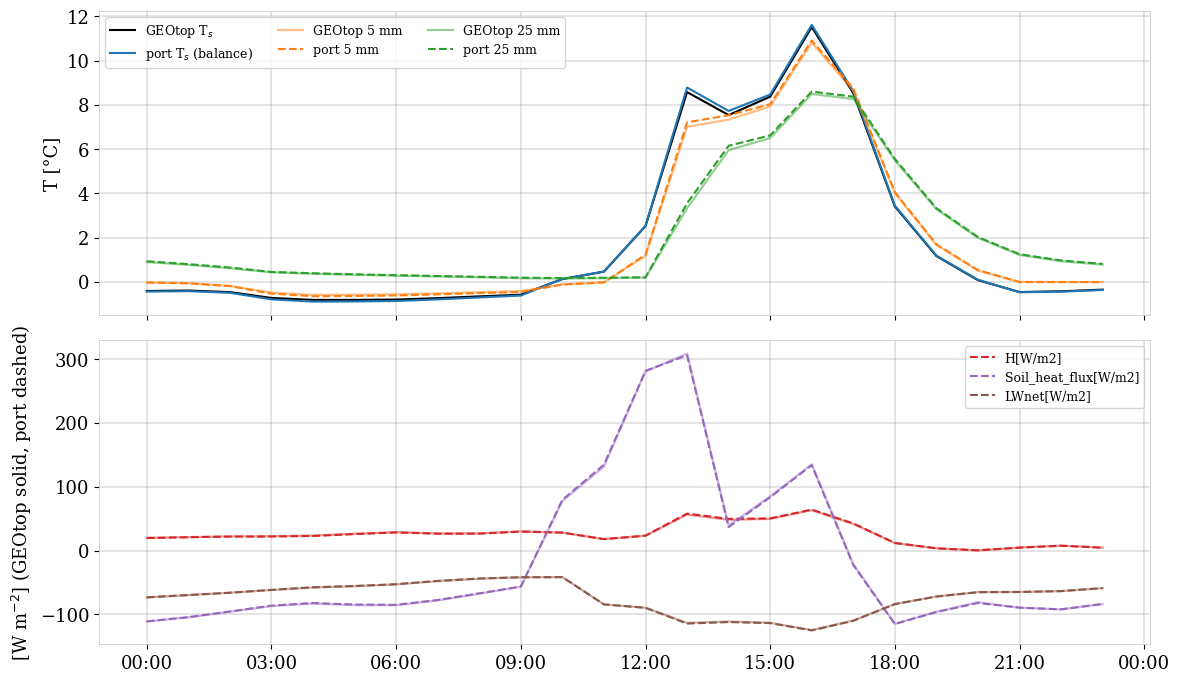

In [16]:
day = slice('2009-10-15 00:00', '2009-10-15 23:00')
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(gt.loc[day].index.to_numpy(), gt.loc[day, 'Tsurface[C]'].to_numpy(), 'k', label='GEOtop T$_s$')
ax[0].plot(ours_seb.loc[day].index.to_numpy(), ours_seb.loc[day, 'Tsurface[C]'].to_numpy(), 'C0', label='port T$_s$ (balance)')
for d, color in [(5.0, 'C1'), (25.0, 'C2')]:
    ax[0].plot(T_gt.loc[day].index.to_numpy(), T_gt.loc[day, d].to_numpy(), color=color, lw=1.6, alpha=0.5, label=f'GEOtop {d:.0f} mm')
    ax[0].plot(T_seb.loc[day].index.to_numpy(), T_seb.loc[day, d].to_numpy(), color=color, ls='--', label=f'port {d:.0f} mm')
ax[0].set_ylabel('T [°C]')
ax[0].legend(ncol=3, fontsize=9)
for col, color in [('H[W/m2]', 'C3'), ('Soil_heat_flux[W/m2]', 'C4'), ('LWnet[W/m2]', 'C5')]:
    ax[1].plot(gt.loc[day].index.to_numpy(), gt.loc[day, col].to_numpy(), color=color, lw=1.6, alpha=0.5)
    ax[1].plot(ours_seb.loc[day].index.to_numpy(), ours_seb.loc[day, col].to_numpy(), color=color, ls='--', label=col)
ax[1].set_ylabel('[W m$^{-2}$] (GEOtop solid, port dashed)')
ax[1].legend(fontsize=9)
for a in ax:
    a.grid(color='grey', linestyle='-', linewidth=0.3)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.tight_layout()

**Reading the balance run.**

- **Bare-soil fluxes match GEOtop.** H, LWnet and SWnet are within 1–2 W m⁻² RMSE and the heat flux into the soil within about 5 W m⁻². The latent heat agrees because its evaporation is GEOtop's.
- **Soil temperature is within tolerance at every depth,** compared as hourly means like GEOtop's. RMSE is 0.14 K at 5 mm, the surface temperature without snow is within 0.11 K, and the bias is at most 0.04 K.
- **The "faster thaw" first reported was not physics.** It was the comparison of the column's end-of-hour temperatures with GEOtop's hourly means. On 15 October between 12:00 and 13:00 the top centimetres warm by 6–9 K within the hour. GEOtop's own energy bookkeeping shows it: computed from its averaged profile, its soil gains only 0.72 MJ m⁻² in that hour against 1.11 MJ m⁻² entering at the surface. The column's averaged values match GEOtop's: 6.96 against 7.00 °C at 5 mm, and 4.52 against 4.50 °C at 15 mm.
- **The snow events** see the same bare soil before and after; the snow metrics move little.
- **Evaporation stays a conditioned input** (LINK-2).